# 02 · Types et nettoyage (jalon M2)

**Objectif :** dates converties dans le bon fuseau horaire, doublons recherchés, colonnes inutiles supprimées, valeurs manquantes traitées. **Chaque choix est justifié par un chiffre** imprimé dans ce notebook.

Résultat : un fichier propre `data/processed/comptages_propres.pkl`, utilisé par les notebooks suivants.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

CHEMIN = Path("data/raw/comptages.csv")
TYPES = {
    "iu_ac": "string", "iu_nd_amont": "string", "iu_nd_aval": "string",
    "libelle_nd_amont": "string", "libelle_nd_aval": "string",
    "libelle": "category", "etat_trafic": "category", "etat_barre": "category",
}
morceaux = [c for c in pd.read_csv(CHEMIN, sep=";", encoding="utf-8-sig", dtype=TYPES, chunksize=50_000)]
df = pd.concat(morceaux, ignore_index=True)
n_depart = len(df)
print(f"{n_depart:,} lignes au départ")

104,736 lignes au départ


## 1. Dates et fuseau horaire
`t_1h` est du texte du type `2026-03-01T00:00:00+01:00`. Le décalage (`+01:00` en hiver, `+02:00` en été) montre que l'heure est exprimée en heure locale de Paris, avec changement d'heure.

**Méthode sûre :** convertir d'abord en UTC (`utc=True`, qui lit correctement tous les décalages), puis passer en `Europe/Paris`. Mélanger des décalages différents sans `utc=True` donne une colonne de type `object`, inutilisable.

In [2]:
print(df["t_1h"].str[-6:].value_counts())      # décalages présents dans le texte
df["t_1h"] = pd.to_datetime(df["t_1h"], utc=True).dt.tz_convert("Europe/Paris")
print(df["t_1h"].dtype)
print(df["t_1h"].min(), "→", df["t_1h"].max())

t_1h
+00:00    104736
Name: count, dtype: int64
datetime64[ns, Europe/Paris]
2026-03-01 01:00:00+01:00 → 2026-09-01 01:00:00+02:00


**Vérification du changement d'heure.** En 2026, le passage à l'heure d'été a lieu le dimanche 29 mars : ce jour-là, il n'y a que **23 heures** (2h-3h n'existe pas). Si la conversion est correcte, on doit le retrouver.

In [3]:
heures_par_jour = df.groupby(df["t_1h"].dt.date)["t_1h"].nunique()
print(heures_par_jour.value_counts().sort_index())
print("29 mars 2026 :", heures_par_jour.get(pd.Timestamp("2026-03-29").date()), "heures distinctes")

t_1h
1       2
2       1
20      1
23      4
24    177
Name: count, dtype: int64
29 mars 2026 : 23 heures distinctes


## 2. Doublons
Deux niveaux : (a) lignes **entièrement identiques** ; (b) plusieurs lignes pour le **même tronçon à la même heure** (la clé naturelle `iu_ac` + `t_1h` doit être unique).

In [4]:
cle = ["iu_ac", "t_1h"]
print("Doublons complets   :", df.duplicated().sum())
print("Doublons sur la clé :", df.duplicated(cle).sum())

Doublons complets   : 0
Doublons sur la clé : 0


In [5]:
# (a) supprimer les lignes identiques
df = df.drop_duplicates()
# (b) pour une même clé, garder la ligne la plus complète (moins de NaN)
df["_nb_nan"] = df[["q", "k", "etat_trafic", "etat_barre"]].isna().sum(axis=1)
df = (df.sort_values(cle + ["_nb_nan"]).drop_duplicates(cle, keep="first")
        .drop(columns="_nb_nan").sort_values(cle).reset_index(drop=True))
print(f"{n_depart - len(df)} lignes supprimées ({(n_depart - len(df)) / n_depart:.2%})")
print("Doublons restants sur la clé :", df.duplicated(cle).sum())

0 lignes supprimées (0.00%)
Doublons restants sur la clé : 0


**Pourquoi garder la ligne la plus complète ?** Si deux lignes décrivent la même heure, celle qui a le moins de valeurs manquantes contient le plus d'information. Supprimer au hasard pourrait garder la ligne vide.

## 3. Colonnes inutiles
On supprime une colonne si elle est **redondante** (déjà dans une autre) ou **sans variation** (aucune information).

In [6]:
# Le libellé d'un carrefour est-il déterminé par son identifiant ?
for c_id, c_lib in [("iu_nd_amont", "libelle_nd_amont"), ("iu_nd_aval", "libelle_nd_aval")]:
    n_max = df.groupby(c_id)[c_lib].nunique().max()
    print(f"{c_id} -> {c_lib} : au plus {n_max} libellé(s) par identifiant")
print()
print(df.nunique().sort_values())

iu_nd_amont -> libelle_nd_amont : au plus 1 libellé(s) par identifiant
iu_nd_aval -> libelle_nd_aval : au plus 1 libellé(s) par identifiant

libelle                 3
etat_barre              3
etat_trafic             5
iu_nd_amont            16
iu_nd_aval             16
libelle_nd_aval        16
libelle_nd_amont       16
iu_ac                  24
q                     878
t_1h                 4364
k                   23329
dtype: int64


In [7]:
# 1 identifiant = 1 libellé  =>  les libellés sont redondants (on garde les codes)
df = df.drop(columns=["libelle_nd_amont", "libelle_nd_aval"])
# On renomme `libelle` en `axe` : c'est le nom de l'axe, plus clair pour la suite
df = df.rename(columns={"libelle": "axe"})
df.columns.tolist()

['iu_ac',
 'axe',
 't_1h',
 'q',
 'k',
 'etat_trafic',
 'iu_nd_amont',
 'iu_nd_aval',
 'etat_barre']

**Choix :** `libelle_nd_amont` / `libelle_nd_aval` sont supprimées (redondantes avec les codes `iu_nd_*`, qui suffisent à identifier un carrefour). `iu_nd_amont` / `iu_nd_aval` sont conservées, elles décrivent la topologie du réseau.

## 4. Que veulent dire `Barré` et `Invalide` ?

In [8]:
print(df["etat_barre"].value_counts(dropna=False))
print()
print(df.groupby("etat_barre", observed=True)[["q", "k"]].agg(["count", "mean", "max"]).round(1))

etat_barre
Ouvert      102627
Invalide      2106
Barré            3
Name: count, dtype: int64

                 q                      k           
             count   mean     max   count mean   max
etat_barre                                          
Barré            3  109.3   213.0       3  1.5   3.3
Invalide         0    NaN     NaN       0  NaN   NaN
Ouvert      101992  271.8  5479.0  102562  4.2  93.2


Un tronçon **barré** (fermé à la circulation) ou **invalide** (capteur en défaut) ne produit pas de mesure fiable : un débit de 0 sur un tronçon barré ne veut pas dire « route vide », il veut dire « route fermée ». On ne doit pas mélanger ces valeurs avec de vrais comptages.

**Choix :** on met `q` et `k` à `NaN` quand `etat_barre` est `Barré` ou `Invalide` (on garde la ligne pour pouvoir compter les fermetures).

In [9]:
non_ouvert = df["etat_barre"].isin(["Barré", "Invalide"])
print(f"{non_ouvert.sum()} lignes concernées ({non_ouvert.mean():.2%})")
df.loc[non_ouvert, ["q", "k"]] = np.nan

2109 lignes concernées (2.01%)


## 5. Valeurs manquantes
### 5.1 Combien, et où ?

In [10]:
print(df[["q", "k", "etat_trafic", "etat_barre"]].isna().mean().round(3))
manq_troncon = (df.assign(q_nan=df["q"].isna(), k_nan=df["k"].isna())
                  .groupby(["axe", "iu_ac"], observed=True)[["q_nan", "k_nan"]].mean().round(3)
                  .sort_values("k_nan", ascending=False))
manq_troncon.head(8)

q              0.026
k              0.021
etat_trafic    0.000
etat_barre     0.000
dtype: float64


q_nan  k_nan
axe               iu_ac              
Bd_Richard_Lenoir 410    0.046  0.047
                  409    0.045  0.047
                  1321   0.046  0.047
                  1320   0.045  0.047
                  1318   0.046  0.045
                  1319   0.045  0.045
                  1317   0.045  0.045
                  1314   0.046  0.045

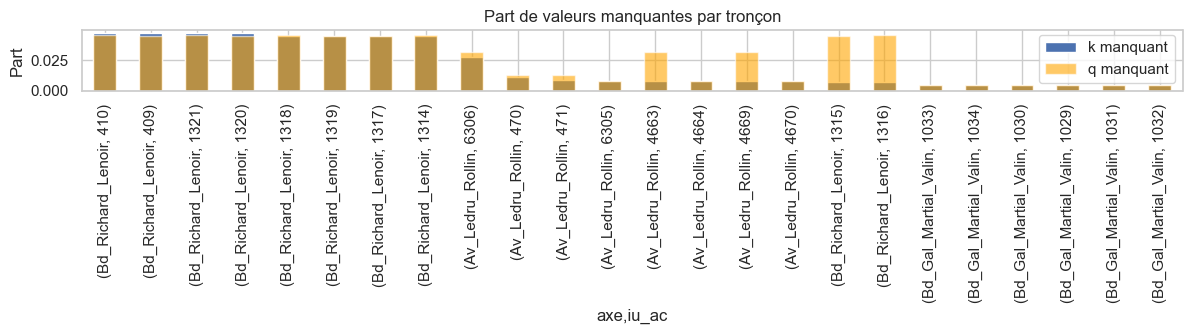

In [11]:
fig, ax = plt.subplots(figsize=(12, 3.5))
manq_troncon["k_nan"].plot.bar(ax=ax, label="k manquant")
manq_troncon["q_nan"].plot.bar(ax=ax, color="orange", alpha=.6, label="q manquant")
ax.set(title="Part de valeurs manquantes par tronçon", ylabel="Part")
ax.legend(); plt.tight_layout(); plt.show()

**Comment lire :** si certains tronçons ont une part de manquants bien plus élevée que les autres, le capteur concerné est probablement en panne ou mal configuré (le problème est *localisé*, pas aléatoire).

### 5.2 `Inconnu` est-il un état ?

In [12]:
print(pd.crosstab(df["etat_trafic"], df["k"].isna(), margins=True, dropna=False)
        .rename(columns={False: "k présent", True: "k manquant"}))

k            k présent  k manquant     All
etat_trafic                               
Bloqué            1009           0    1009
Fluide           97178           3   97181
Inconnu              0        2171    2171
Pré-saturé        2875           0    2875
Saturé            1500           0    1500
All             102562        2174  104736


Si tous les `Inconnu` correspondent à `k` manquant (et inversement), alors `Inconnu` n'est **pas un état du trafic** mais une **absence de mesure** déguisée en catégorie.

**Choix :** on remplace `Inconnu` par `NaN` pour que l'absence soit traitée comme telle (sinon elle serait comptée comme une catégorie à part entière dans les statistiques et les graphiques).

In [13]:
df["etat_trafic"] = (df["etat_trafic"].mask(df["etat_trafic"] == "Inconnu")
                                      .cat.remove_unused_categories())
print(df["etat_trafic"].value_counts(dropna=False))

etat_trafic
Fluide        97181
Pré-saturé     2875
NaN            2171
Saturé         1500
Bloqué         1009
Name: count, dtype: int64


### 5.3 Que fait-on des manquants de `q` et `k` ?
Options :
1. **Supprimer** les lignes où les deux sont absents : la ligne n'apporte aucune mesure.
2. **Imputer** (moyenne, interpolation) : risqué, car on inventerait du trafic ; en plus, imputer par la moyenne lisserait justement les pics qu'on veut étudier.
3. **Laisser `NaN`** quand un seul des deux manque : pandas ignore les `NaN` dans les moyennes, et `q` reste exploitable même si `k` manque.

**Choix :** supprimer les lignes sans aucune mesure, laisser les `NaN` isolés, ne pas imputer.

In [14]:
sans_mesure = df["q"].isna() & df["k"].isna()
print(f"Lignes sans aucune mesure : {sans_mesure.sum()} ({sans_mesure.mean():.2%})")
df = df[~sans_mesure].reset_index(drop=True)
print(f"q manquant restant : {df['q'].isna().mean():.2%} | k manquant restant : {df['k'].isna().mean():.2%}")

Lignes sans aucune mesure : 2109 (2.01%)
q manquant restant : 0.62% | k manquant restant : 0.06%


## 6. Sauvegarde et bilan

In [15]:
Path("data/processed").mkdir(parents=True, exist_ok=True)
df.to_pickle("data/processed/comptages_propres.pkl")     # pickle : conserve les types (dates, catégories)
print(df.dtypes)
print()
print(f"Lignes : {n_depart:,} -> {len(df):,} ({1 - len(df) / n_depart:.1%} retirées au total)")

iu_ac                        string[python]
axe                                category
t_1h           datetime64[ns, Europe/Paris]
q                                   float64
k                                   float64
etat_trafic                        category
iu_nd_amont                  string[python]
iu_nd_aval                   string[python]
etat_barre                           object
dtype: object

Lignes : 104,736 -> 102,627 (2.0% retirées au total)


### Bilan M2 (à recopier dans le README)
| Problème | Constat | Décision |
|---|---|---|
| Dates | texte avec décalage +01:00 / +02:00 | `to_datetime(utc=True)` puis `Europe/Paris` ; 23 h le 29 mars vérifié |
| Doublons | voir chiffres §2 | suppression, en gardant la ligne la plus complète |
| Colonnes | libellés des carrefours redondants avec les codes | supprimés ; `libelle` renommée `axe` |
| `Barré` / `Invalide` | mesures non fiables | `q` et `k` mis à `NaN` |
| `Inconnu` | = absence de `k` | remplacé par `NaN` |
| Manquants | q et k absents ensemble | lignes supprimées ; pas d'imputation |